# NOMe-HiC meningioma QC plots (snakemake pipeline)

QC summary, histograms, and **per-batch** plots for the consolidated meningioma
workdir (all three data batches together), using the same logic as
`sc_nomehic_cellline/snakemake/qc_plots.ipynb`.

**Three batches** (prefixes collide on `split('_')[0]`, so batch is assigned explicitly):

| batch | prefix pattern | n cells |
|-------|----------------|---------|
| batch1 | `MY_*` | 176 |
| batch2 | `NU04113_*` (not p2) | 92 |
| batch3 | `NU04113_scNOMe_HiC_p2_*` | 80 |

**Inputs (per cell):**
- `04.alignment_snakemake/{cell}.summary.txt.gz` — Hi-C alignment stats
- `07.bistools_snakemake/qc/{cell}/{cell}.calmd.trinuc_methy.{chrM,chr21}.txt.gz` — methylation QC
- `07.bistools_snakemake/methylation/{cell}/{cell}.cyt.filtered.sort.{GCH,HCG}.6plus2.bed.gz` — site counts

**Outputs:** `QC/meningioma_*` tables, `figures/meningioma_*.pdf`, `QC/meningioma_passed.txt`,
per-batch overlay/violin figures, and `QC/methylation_matrices/`.

QC thresholds come from `config.yaml` (shared filter, identical to the cortex project):
`fragnum>1e5, noncpg<5, GCH>1e6, HCG>1.5e5, cis1kbnum>2000`; no transrate / cisnum_max bound.


In [ ]:
# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has chdir'd away.
import os as _os, sys as _sys
if "REPO_ROOT" not in globals():
    _r = _os.getcwd()
    while _r != "/" and not _os.path.exists(_os.path.join(_r, "paths.py")):
        _r = _os.path.dirname(_r)
    assert _os.path.exists(_os.path.join(_r, "paths.py")), \
        "paths.py not found above the working directory -- start Jupyter inside the repository"
    REPO_ROOT = _r
_sys.path.insert(0, REPO_ROOT)
from paths import DATA, REFERENCE, SOFTWARE, WORK, TMP, CONDA_SH, CONDA_ENVS

import gzip
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from matplotlib.backends.backend_pdf import PdfPages
from tqdm.auto import tqdm

WORKDIR = Path(WORK + '/meningioma')
os.chdir(WORKDIR)

ALIGN_DIR = WORKDIR / '04.alignment_snakemake'
QC_DIR    = WORKDIR / '07.bistools_snakemake' / 'qc'
METH_DIR  = WORKDIR / '07.bistools_snakemake' / 'methylation'
OUT_QC    = WORKDIR / 'QC'
OUT_FIG   = WORKDIR / 'figures'
OUT_QC.mkdir(exist_ok=True)
OUT_FIG.mkdir(exist_ok=True)

with open('config.yaml') as f:
    CFG = yaml.safe_load(f)

THRESHOLDS = {
    'fragnum_threshold':   CFG['fragnum_threshold'],
    'noncpg_threshold':    CFG['noncpg_threshold'],
    'GCH_threshold':       CFG['GCH_threshold'],
    'HCG_threshold':       CFG['HCG_threshold'],
    'cis1kbnum_threshold': CFG['cis1kbnum_threshold'],
    # Upper bound on cisnum to drop suspected doublets; absent -> +inf (cortex-style, no bound).
    'cisnum_max_threshold': CFG.get('cisnum_max_threshold', float('inf')),
}


import re as _re
def assign_batch(prefix):
    """Map a cell prefix to its group = sample_plate (replaces batch1/2/3):
    sample1 = MY_ (plate1 = MY_1..24, plate2 = MY_25..48);
    sample2 = NU04113 (plate1 = NU04113_<n>_S, plate2 = NU04113_scNOMe_HiC_p2_*)."""
    if prefix.startswith('NU04113_scNOMe_HiC_p2_'):
        return 'sample2_plate2'
    if prefix.startswith('NU04113_'):
        return 'sample2_plate1'
    if prefix.startswith('MY_'):
        m = _re.match(r'MY_(\d+)_', prefix)
        n = int(m.group(1)) if m else 999
        return 'sample1_plate1' if n <= 24 else 'sample1_plate2'
    return 'unknown'


BATCH_ORDER = ['sample1_plate1', 'sample1_plate2', 'sample2_plate1', 'sample2_plate2']
print('Workdir:', WORKDIR)
print('QC thresholds:', THRESHOLDS)


In [ ]:
def summarize_meningioma_qc_from_data(
    prefixes,
    gch_hcg_df,
    chrm_df,
    chr21_df,
    summary_files,
    dataset_label='meningioma',
    output_file=None,
    summary_pdf=None,
    utilized_cell_output=None,
    fragnum_threshold=100000,
    noncpg_threshold=5,
    GCH_threshold=1_000_000,
    HCG_threshold=150_000,
    cis1kbnum_threshold=2000,
    cisnum_max_threshold=float('inf'),
    show_inline=False,
    summary_pdf_p99=None,
    clip_percentile_p99=99,
    clip_only_if_outlier=True,
):
    """Summarize QC metrics, plot histograms, and write the QC-passing cell list."""

    def plot_hist(df, column, title, xlabel, pdf=None, threshold=None,
                  clip_percentile=None, clip_only_if_outlier=False):
        plt.figure(figsize=(8, 5))
        subset = df[column].dropna()
        if subset.empty:
            plt.close(); return
        plot_vals = subset; title_use = title; bins = 50
        if clip_percentile is not None:
            x_hi = np.percentile(subset, clip_percentile)
            n_above = int((subset > x_hi).sum())
            if (n_above > 0) if clip_only_if_outlier else True:
                plot_vals = subset[subset <= x_hi]
                bins = np.linspace(plot_vals.min(), x_hi, 51)
                if n_above > 0:
                    title_use = f"{title} (x <= p{clip_percentile:.0f}={x_hi:.4g}; {n_above} above)"
        plt.hist(plot_vals, bins=bins, alpha=0.7, color='steelblue', edgecolor='black')
        if threshold is not None:
            plt.axvline(threshold, color='red', linestyle='--', linewidth=1.5, label='threshold')
            plt.legend()
        plt.title(title_use); plt.xlabel(xlabel); plt.ylabel('Frequency')
        if pdf: pdf.savefig()
        if show_inline: plt.show()
        plt.close()

    chrm_df = chrm_df.copy()
    chrm_df.columns = ['noncpg_chrM', 'endo_chrM', 'exo_chrM']

    all_entries = []
    for prefix, summ_path in tqdm(zip(prefixes, summary_files), total=len(prefixes),
                                  desc='Parsing QC summaries'):
        _grp = assign_batch(prefix)
        _seq = ('batch3' if prefix.startswith('NU04113_scNOMe_HiC_p2_') else
                'batch2' if prefix.startswith('NU04113_') else
                'batch1' if prefix.startswith('MY_') else 'other')
        entry = {'prefix': prefix, 'dataset': dataset_label, 'batch': _grp,
                 'sample': _grp.split('_')[0], 'plate': _grp.split('_')[-1], 'seqbatch': _seq}
        try:
            a = pd.read_csv(summ_path, sep='\t', header=None)
            g = lambda k: a[a[0] == k]
            entry.update({
                'uniquemap':  float(g('UniqMapped:')[2].values[0].strip('%')),
                'mapq30rate': float(g('UniqMappedMapQ30:')[2].values[0].strip('%')),
                'mapq30num':  int(g('UniqMappedMapQ30:')[1].values[0]),
                'fragnum':    int(g('TotalFragments:')[1].values[0]),
                'cisnum':     int(g('UniqMappedMapQ30NoPcrCis:')[1].values[0]),
                'cis1kbnum':  int(g('UniqMappedMapQ30NoPcrCisMore1kb:')[1].values[0]),
                'transnum':   int(g('UniqMappedMapQ30NoPcrTrans:')[1].values[0]),
                'cis1kbrate': float(g('UniqMappedMapQ30NoPcrCisMore1kb:')[2].values[0].strip('%')),
                'transrate':  float(g('UniqMappedMapQ30NoPcrTrans:')[2].values[0].strip('%')),
            })
        except Exception:
            entry.update({k: np.nan for k in
                          ['uniquemap','mapq30rate','mapq30num','fragnum','cisnum',
                           'cis1kbnum','transnum','cis1kbrate','transrate']})
        entry.update(chrm_df.loc[prefix].to_dict() if prefix in chrm_df.index
                     else {'noncpg_chrM': np.nan, 'endo_chrM': np.nan, 'exo_chrM': np.nan})
        entry.update(chr21_df.loc[prefix].to_dict() if prefix in chr21_df.index
                     else {'noncpg': np.nan, 'endo': np.nan, 'exo': np.nan})
        entry.update(gch_hcg_df.loc[prefix].to_dict() if prefix in gch_hcg_df.index
                     else {'GCH': np.nan, 'HCG': np.nan})
        all_entries.append(entry)

    df = pd.DataFrame(all_entries)
    if output_file:
        df.to_csv(output_file, sep='\t', index=False)
        print(f'Saved summary table: {output_file}')

    plot_columns = [
        ('fragnum', 'Raw fragment number', '# of fragments'),
        ('uniquemap', 'Unique mapping rate', 'Mapping rate (%)'),
        ('mapq30rate', 'Fragments MAPQ>30 rate', 'MAPQ>30 (%)'),
        ('mapq30num', 'Reads passing MAPQ>30', '# of reads'),
        ('cisnum', 'Cis interactions for Hi-C', '# of cis interactions'),
        ('transnum', 'Trans interactions for Hi-C', '# of trans interactions'),
        ('cis1kbnum', 'Cis interactions >1kb Hi-C', '# of cis interactions'),
        ('transrate', 'Trans interaction rate Hi-C', 'Trans rate (%)'),
        ('cis1kbrate', 'Cis >1kb interaction rate Hi-C', 'Cis >1kb rate (%)'),
        ('noncpg_chrM', 'Non-CpG methylation rate (chrM)', '% methylation'),
        ('endo_chrM', 'Endogenous methylation rate (chrM)', '% methylation'),
        ('exo_chrM', 'Exogenous methylation rate (chrM)', '% methylation'),
        ('noncpg', 'Non-CpG methylation rate (chr21)', '% methylation'),
        ('endo', 'Endogenous methylation rate (chr21)', '% methylation'),
        ('exo', 'Exogenous methylation rate (chr21)', '% methylation'),
        ('GCH', 'Number of GCH sites', 'Number of sites'),
        ('HCG', 'Number of HCG sites', 'Number of sites'),
    ]
    thresholds = {'fragnum': fragnum_threshold, 'noncpg': noncpg_threshold,
                  'noncpg_chrM': noncpg_threshold, 'GCH': GCH_threshold,
                  'HCG': HCG_threshold, 'cis1kbnum': cis1kbnum_threshold,
                  # cisnum upper bound (doublet/high-depth cap); skip line if unset (inf)
                  'cisnum': (cisnum_max_threshold if np.isfinite(cisnum_max_threshold) else None)}

    pdf_jobs = []
    if summary_pdf:     pdf_jobs.append((summary_pdf, None, False))
    if summary_pdf_p99: pdf_jobs.append((summary_pdf_p99, clip_percentile_p99, clip_only_if_outlier))
    for pdf_path, clip_p, clip_if_out in pdf_jobs:
        with PdfPages(pdf_path) as pdf:
            for col, title, xlabel in plot_columns:
                plot_hist(df, col, title, xlabel, pdf, thresholds.get(col),
                          clip_percentile=clip_p, clip_only_if_outlier=clip_if_out)
        print(f'Saved summary PDF: {pdf_path}')

    df_filtered = df[
        (df['fragnum'] > fragnum_threshold) &
        (df['noncpg'] < noncpg_threshold) &
        (df['noncpg_chrM'] < noncpg_threshold) &
        (df['GCH'] > GCH_threshold) &
        (df['HCG'] > HCG_threshold) &
        (df['cis1kbnum'] > cis1kbnum_threshold) &
        (df['cisnum'] < cisnum_max_threshold)
    ]
    # Drop control / titration wells (blank, 10c/100c/1000c) listed in
    # QC/control_wells.txt — these are not real single cells even if they pass.
    _ctrl = OUT_QC / 'control_wells.txt'
    if _ctrl.exists():
        _cset = set(pd.read_csv(_ctrl, header=None)[0].astype(str))
        _n0 = len(df_filtered)
        df_filtered = df_filtered[~df_filtered['prefix'].isin(_cset)]
        if _n0 != len(df_filtered):
            print(f'Dropped {_n0 - len(df_filtered)} control well(s) from passed list')
    if utilized_cell_output:
        df_filtered['prefix'].to_csv(utilized_cell_output, index=False, header=False)
        print(f'Saved passing cell list: {utilized_cell_output}')
    print(f'{len(df_filtered)}/{len(df)} cells passed QC thresholds')
    return df, df_filtered


In [22]:
TRINUC_SUFFIX_CHRM  = '.calmd.trinuc_methy.chrM.txt.gz'
TRINUC_SUFFIX_CHR21 = '.calmd.trinuc_methy.chr21.txt.gz'
BED_MIDDLE          = '.cyt.filtered.sort.'


def _trinuc_percent(path, trinuc):
    df = pd.read_csv(path, sep='\t', header=None, names=['trinuc', 'count', 'percent'])
    vals = df.loc[df['trinuc'] == f'{trinuc}:', 'percent']
    return np.nan if len(vals) == 0 else float(str(vals.iloc[0]).strip('%'))


def build_trinuc_table(prefixes, suffix):
    rows = []
    for prefix in tqdm(prefixes, desc=f'trinuc {suffix}'):
        path = QC_DIR / prefix / f'{prefix}{suffix}'
        if not path.exists():
            rows.append([prefix, np.nan, np.nan, np.nan]); continue
        rows.append([prefix, _trinuc_percent(path, 'ACT'),
                     _trinuc_percent(path, 'ACG'), _trinuc_percent(path, 'GCT')])
    return pd.DataFrame(rows, columns=['sample', 'noncpg', 'endo', 'exo']).set_index('sample')


def _count_bed_gz(path):
    if not path.exists():
        return np.nan
    with gzip.open(path, 'rt') as f:
        return sum(1 for _ in f)


def build_gch_hcg_table(prefixes):
    rows = []
    for prefix in tqdm(prefixes, desc='GCH/HCG counts'):
        cell = METH_DIR / prefix
        rows.append([prefix,
                     _count_bed_gz(cell / f'{prefix}{BED_MIDDLE}GCH.6plus2.bed.gz'),
                     _count_bed_gz(cell / f'{prefix}{BED_MIDDLE}HCG.6plus2.bed.gz')])
    return pd.DataFrame(rows, columns=['sample', 'GCH', 'HCG']).set_index('sample')


def discover_prefixes(qc_dir=QC_DIR):
    """Cells whose bis-QC finished: a trinuc_methy.chrM.txt.gz exists under qc/<cell>/.
    (The alignment summary lives in 04.alignment_snakemake/, not in the qc folder.)"""
    out = []
    for p in sorted(qc_dir.iterdir()):
        if p.is_dir() and (p / f'{p.name}{TRINUC_SUFFIX_CHRM}').exists():
            out.append(p.name)
    return out


In [23]:
# Discover cells with completed bis-QC outputs
all_prefixes = discover_prefixes()
print(f'Found {len(all_prefixes)} cells with QC outputs')

prefixes = all_prefixes  # no batch subsetting; QC all three batches together
batch_counts = pd.Series([assign_batch(p) for p in prefixes]).value_counts()
print('Cells per batch:')
print(batch_counts.reindex(BATCH_ORDER))

pd.Series(prefixes).to_csv(OUT_QC / 'meningioma_prefixes_used.txt', index=False, header=False)


Found 348 cells with QC outputs
Cells per batch:
batch1    176
batch2     92
batch3     80
Name: count, dtype: int64


In [25]:
# # Build aggregate metric tables (cached to QC/ for re-runs)
# gch_hcg = build_gch_hcg_table(prefixes)
# chrm    = build_trinuc_table(prefixes, TRINUC_SUFFIX_CHRM)
# chr21   = build_trinuc_table(prefixes, TRINUC_SUFFIX_CHR21)

# gch_hcg.to_csv(OUT_QC / 'meningioma.gch_hcg_count.txt', sep='\t')
# chrm.to_csv(OUT_QC / 'meningioma.chrM.txt', sep='\t')
# chr21.to_csv(OUT_QC / 'meningioma.chr21.txt', sep='\t')
# display(gch_hcg.head())


In [26]:
# (re-run shortcut) load cached tables instead of rebuilding
gch_hcg = pd.read_csv(OUT_QC / 'meningioma.gch_hcg_count.txt', sep='\t', index_col=0)
chrm    = pd.read_csv(OUT_QC / 'meningioma.chrM.txt', sep='\t', index_col=0)
chr21   = pd.read_csv(OUT_QC / 'meningioma.chr21.txt', sep='\t', index_col=0)


In [27]:
# Alignment summaries + QC histograms + write meningioma_passed.txt
def _summary_path(p):
    plain = ALIGN_DIR / f'{p}.summary.txt'
    gz    = ALIGN_DIR / f'{p}.summary.txt.gz'
    return str(plain if plain.exists() else gz)
summary_files = [_summary_path(p) for p in prefixes]

df_all, df_passed = summarize_meningioma_qc_from_data(
    prefixes=prefixes,
    gch_hcg_df=gch_hcg, chrm_df=chrm, chr21_df=chr21,
    summary_files=summary_files,
    dataset_label='sc NOMe-HiC meningioma (snakemake)',
    output_file=str(OUT_QC / 'meningioma_qc_summary.txt'),
    summary_pdf=str(OUT_FIG / 'meningioma_summary.pdf'),
    summary_pdf_p99=str(OUT_FIG / 'meningioma_summary_p99.pdf'),
    clip_percentile_p99=99, clip_only_if_outlier=True,
    utilized_cell_output=str(OUT_QC / 'meningioma_passed.txt'),
    show_inline=False,
    **THRESHOLDS,
)
df_all.head()


Parsing QC summaries:   0%|          | 0/348 [00:00<?, ?it/s]

Saved summary table: /gpfs/projects/b1198/epifluidlab/yoshii/meningioma_scnomehic/snakemake/QC/meningioma_qc_summary.txt
Saved summary PDF: /gpfs/projects/b1198/epifluidlab/yoshii/meningioma_scnomehic/snakemake/figures/meningioma_summary.pdf
Saved summary PDF: /gpfs/projects/b1198/epifluidlab/yoshii/meningioma_scnomehic/snakemake/figures/meningioma_summary_p99.pdf
Saved passing cell list: /gpfs/projects/b1198/epifluidlab/yoshii/meningioma_scnomehic/snakemake/QC/meningioma_passed.txt
296/348 cells passed QC thresholds


,prefix,dataset,batch,uniquemap,mapq30rate,mapq30num,fragnum,cisnum,cis1kbnum,transnum,cis1kbrate,transrate,noncpg_chrM,endo_chrM,exo_chrM,noncpg,endo,exo,GCH,HCG
0,MY_10_S193.ATCACG,sc NOMe-HiC meningioma (snakemake),batch1,100.0,50.644134,4027968,7953474,2500967,13022,22517,0.516033,0.892298,0.734,0.490,64.289,0.689,76.050,37.289,11583920,1702402
1,MY_10_S193.CGATGT,sc NOMe-HiC meningioma (snakemake),batch1,100.0,0.285714,2,700,2,0,0,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,27,3
2,MY_10_S193.GCCAAT,sc NOMe-HiC meningioma (snakemake),batch1,100.0,62.213399,3568797,5736380,2176375,13190,17851,0.601123,0.813544,1.201,3.896,72.595,0.681,77.603,46.307,9160897,1323308
3,MY_10_S193.TGACCA,sc NOMe-HiC meningioma (snakemake),batch1,100.0,66.528506,4033783,6063240,2481754,13181,23771,0.526077,0.948743,0.629,1.745,65.892,1.178,78.661,42.591,11435903,1662939
4,MY_11_S194.ATCACG,sc NOMe-HiC meningioma (snakemake),batch1,100.0,49.658636,1519302,3059492,1123070,7089,9064,0.626163,0.800612,0.721,0.000,65.262,0.658,77.137,51.958,5776712,845568


## Per-batch QC

Pass rate, overlaid histograms, and violins across batch1/2/3.

In [28]:
# Pass rate by batch
passed_set = set(df_passed['prefix'])
df_all['passed'] = df_all['prefix'].isin(passed_set)
batch_summary = (df_all.groupby('batch')['passed']
                 .agg(['sum', 'count'])
                 .assign(pass_rate=lambda x: x['sum'] / x['count'])
                 .rename(columns={'sum': 'n_passed', 'count': 'n_total'})
                 .reindex(BATCH_ORDER))
batch_summary


,n_passed,n_total,pass_rate
batch,,,
batch1,154,176,0.875000
batch2,67,92,0.728261
batch3,75,80,0.937500


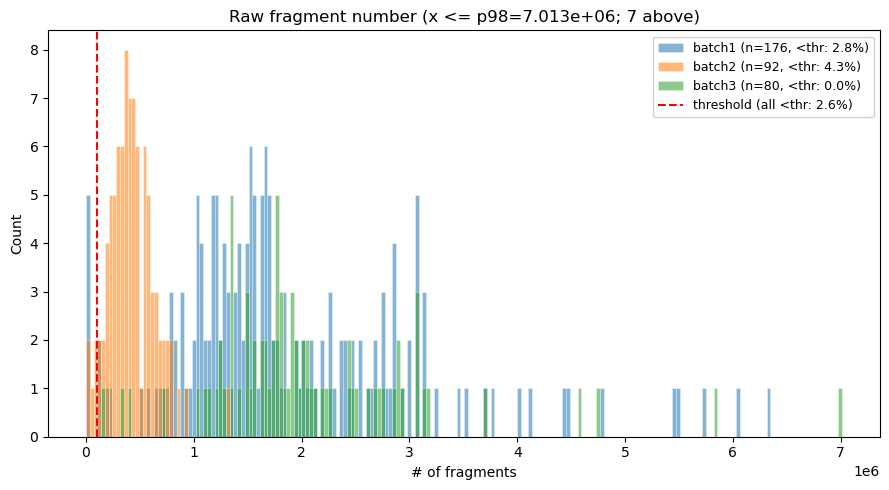

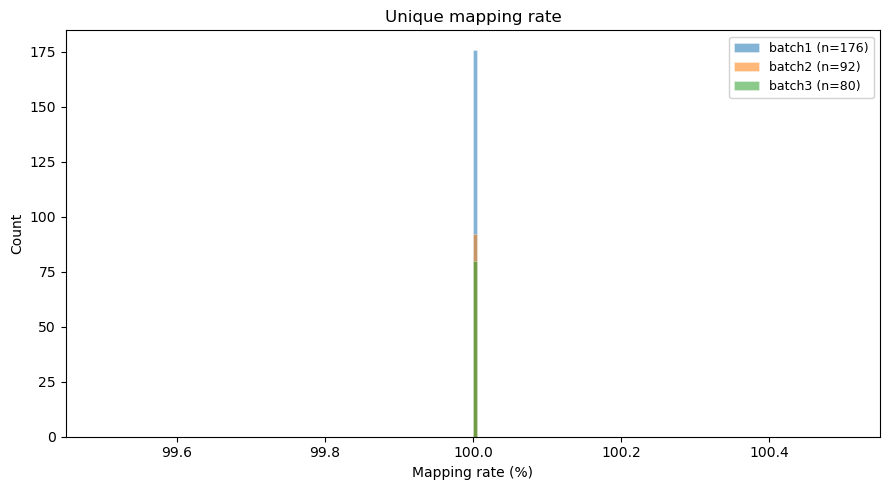

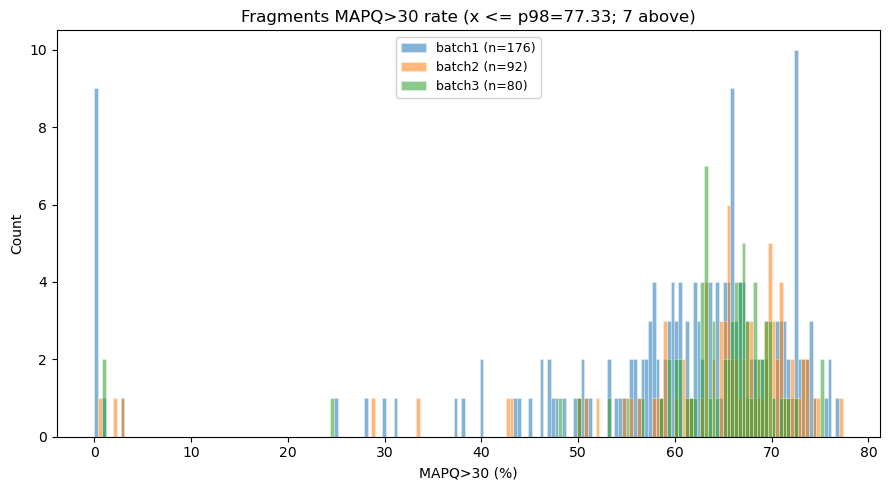

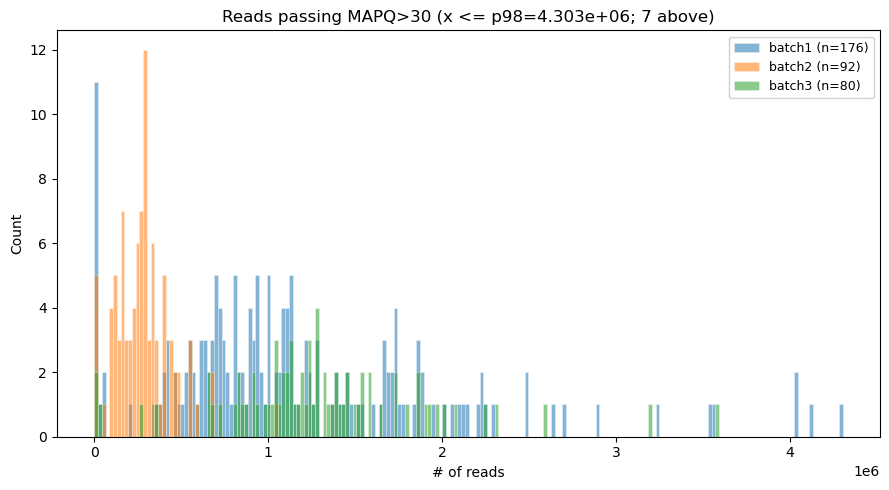

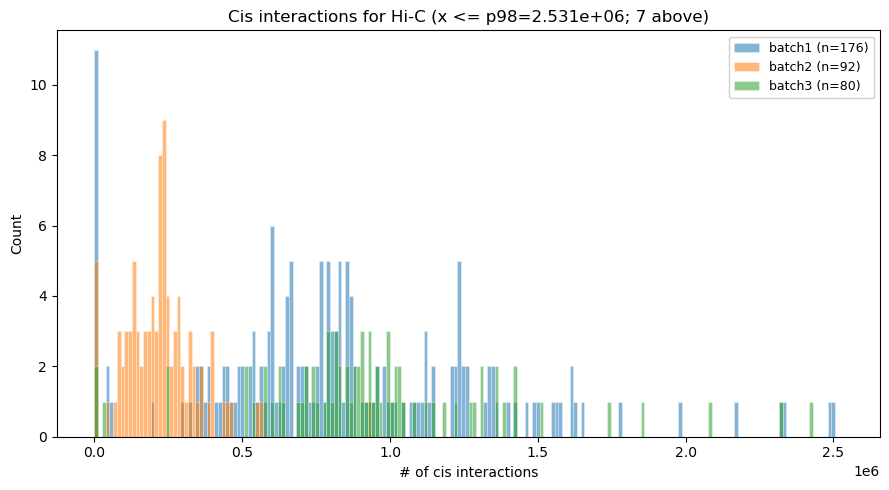

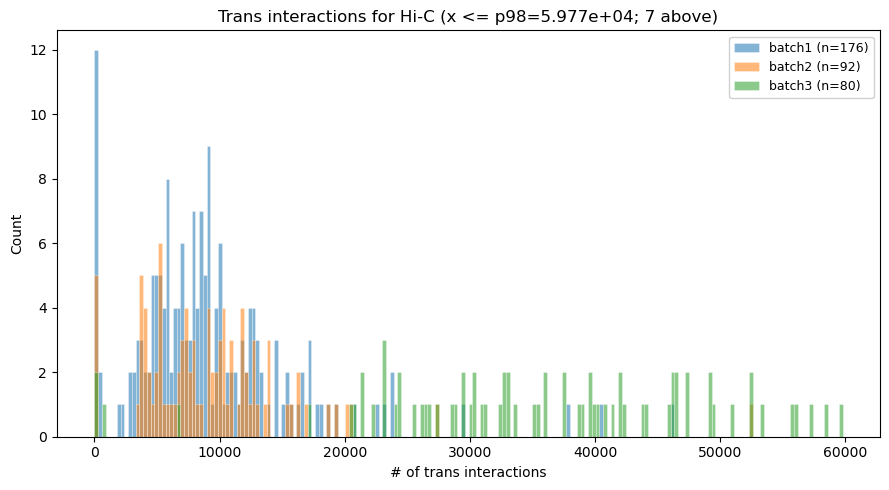

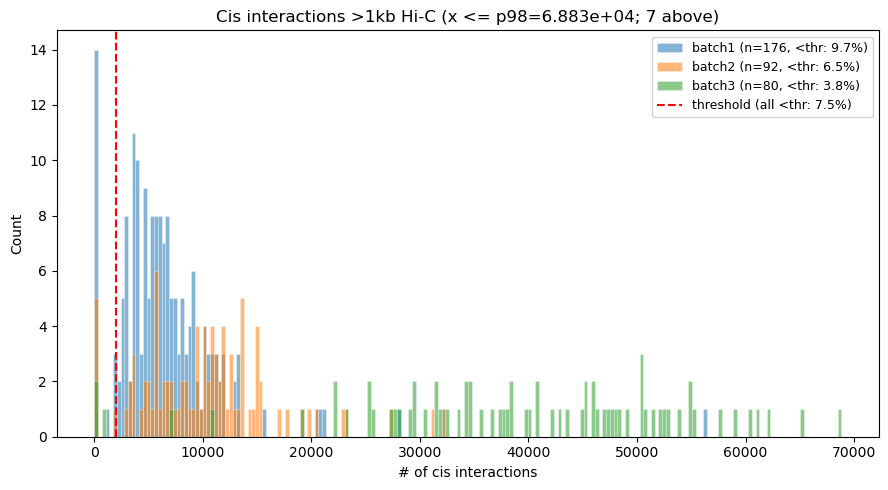

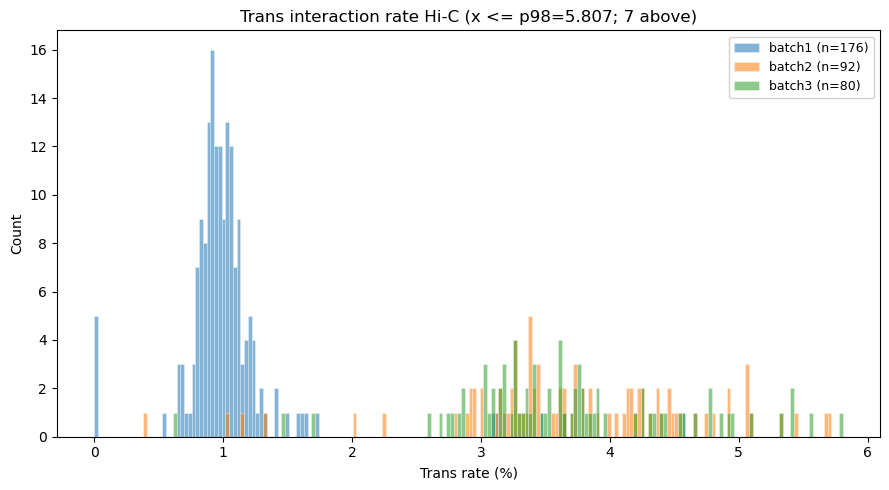

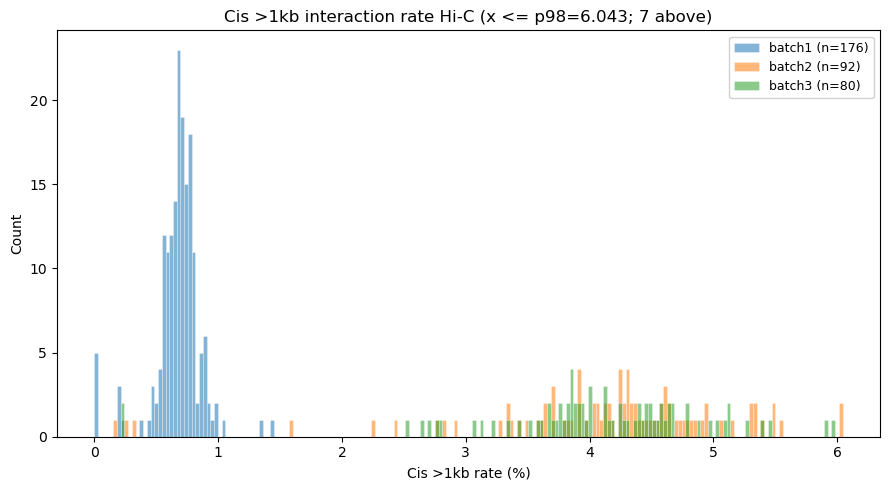

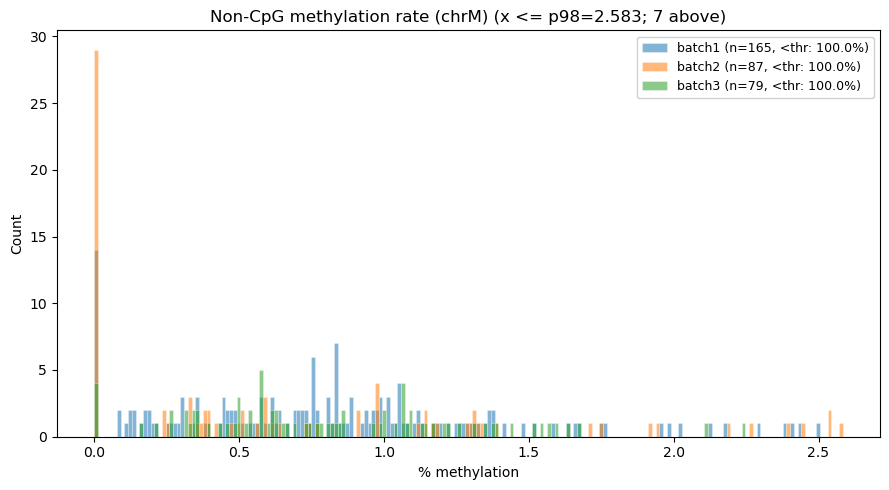

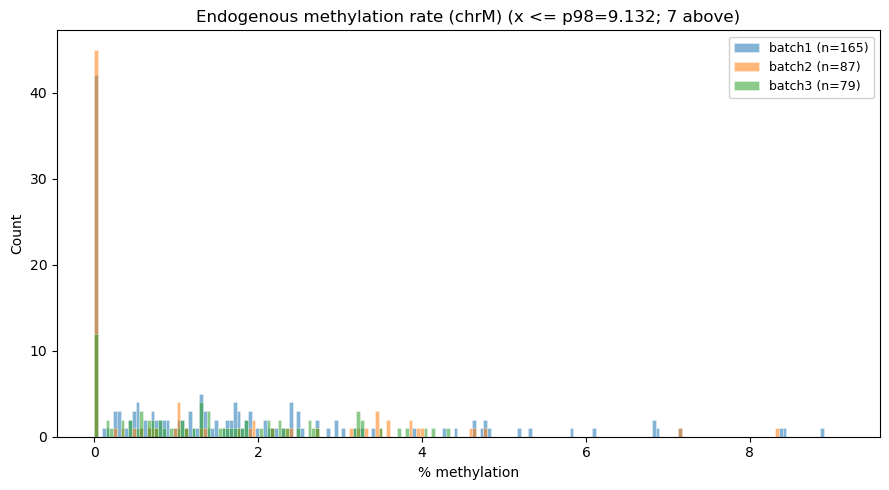

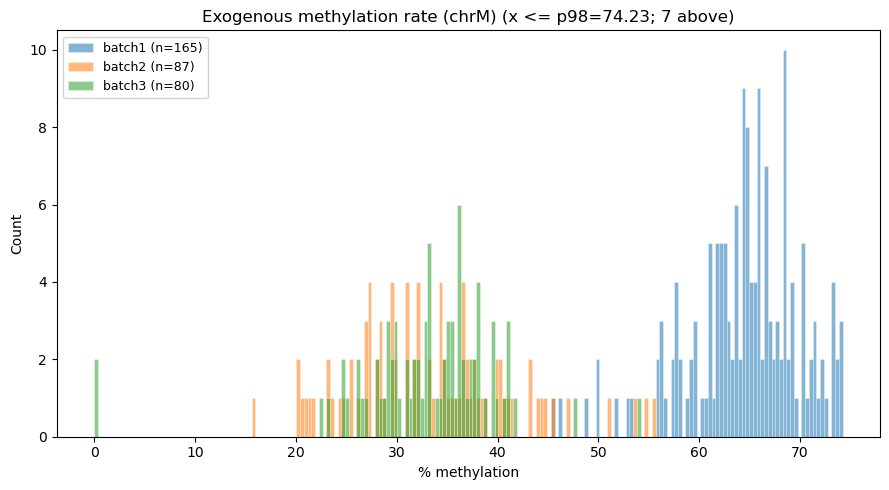

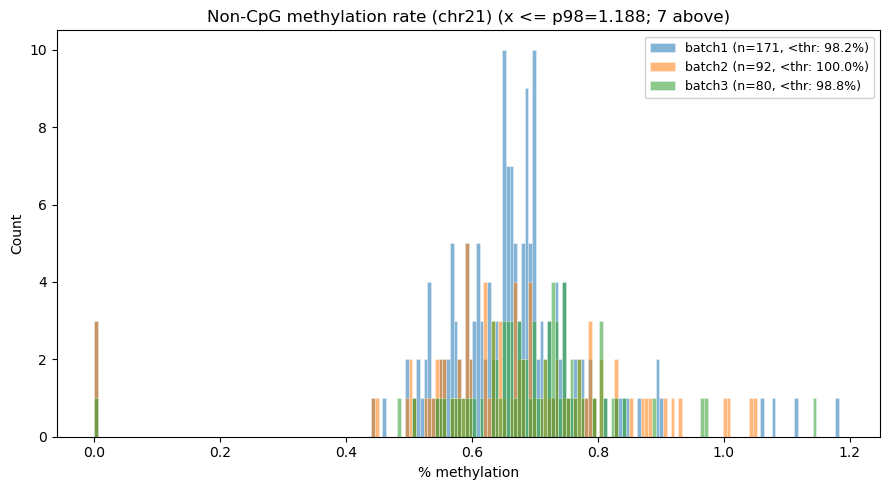

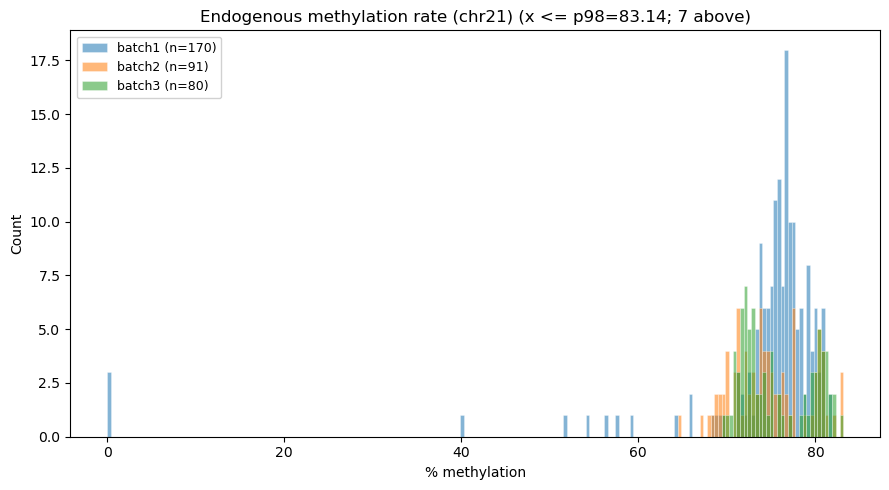

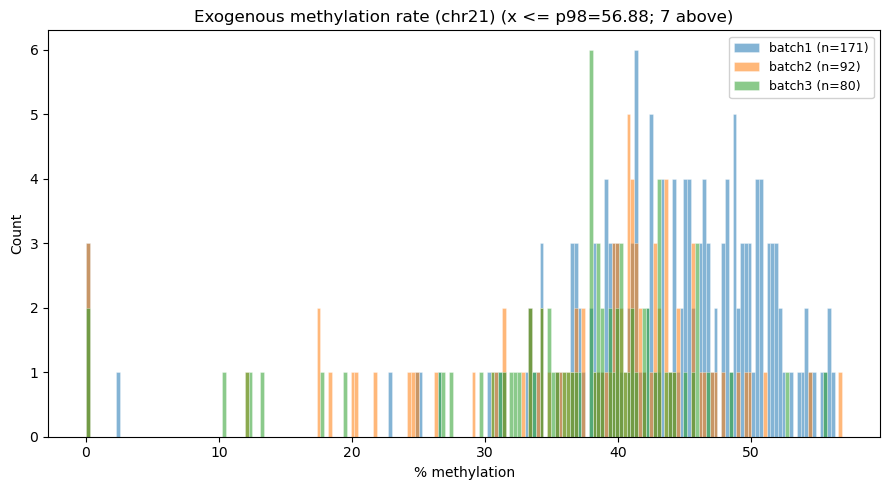

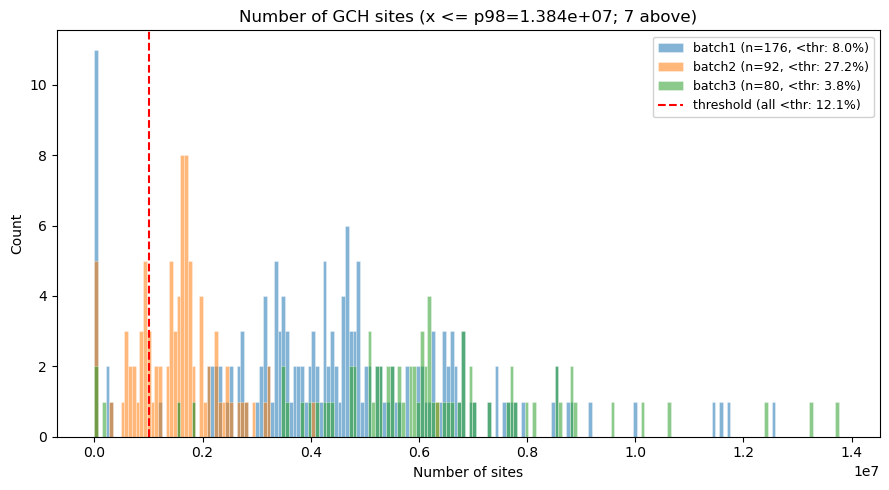

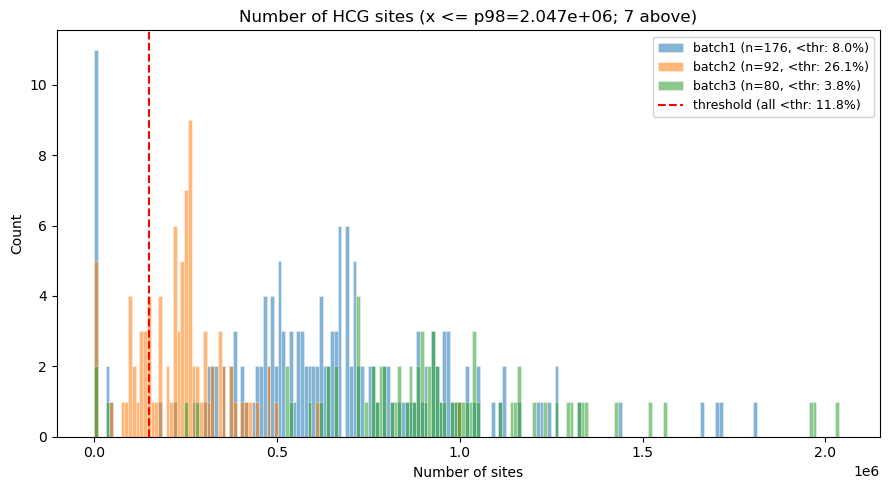

Saved per-batch overlay histograms: /gpfs/projects/b1198/epifluidlab/yoshii/meningioma_scnomehic/snakemake/figures/meningioma_summary_by_batch_p98_if_outlier.pdf


In [29]:
# Per-batch overlay histograms: one panel per metric, batches by color
PLOT_COLUMNS = [
    ('fragnum', 'Raw fragment number', '# of fragments'),
    ('uniquemap', 'Unique mapping rate', 'Mapping rate (%)'),
    ('mapq30rate', 'Fragments MAPQ>30 rate', 'MAPQ>30 (%)'),
    ('mapq30num', 'Reads passing MAPQ>30', '# of reads'),
    ('cisnum', 'Cis interactions for Hi-C', '# of cis interactions'),
    ('transnum', 'Trans interactions for Hi-C', '# of trans interactions'),
    ('cis1kbnum', 'Cis interactions >1kb Hi-C', '# of cis interactions'),
    ('transrate', 'Trans interaction rate Hi-C', 'Trans rate (%)'),
    ('cis1kbrate', 'Cis >1kb interaction rate Hi-C', 'Cis >1kb rate (%)'),
    ('noncpg_chrM', 'Non-CpG methylation rate (chrM)', '% methylation'),
    ('endo_chrM', 'Endogenous methylation rate (chrM)', '% methylation'),
    ('exo_chrM', 'Exogenous methylation rate (chrM)', '% methylation'),
    ('noncpg', 'Non-CpG methylation rate (chr21)', '% methylation'),
    ('endo', 'Endogenous methylation rate (chr21)', '% methylation'),
    ('exo', 'Exogenous methylation rate (chr21)', '% methylation'),
    ('GCH', 'Number of GCH sites', 'Number of sites'),
    ('HCG', 'Number of HCG sites', 'Number of sites'),
]
METRIC_THRESHOLDS = {
    'fragnum': THRESHOLDS['fragnum_threshold'], 'noncpg': THRESHOLDS['noncpg_threshold'],
    'noncpg_chrM': THRESHOLDS['noncpg_threshold'], 'GCH': THRESHOLDS['GCH_threshold'],
    'HCG': THRESHOLDS['HCG_threshold'], 'cis1kbnum': THRESHOLDS['cis1kbnum_threshold'],
}


def plot_histograms_per_batch(df, plot_columns, thresholds, batch_order=None,
                              out_pdf=None, bins=40, show_inline=False,
                              clip_percentile=None, clip_only_if_outlier=False):
    if batch_order is None:
        batch_order = [b for b in BATCH_ORDER if b in set(df['batch'])]
    colors = dict(zip(batch_order, sns.color_palette('tab10', n_colors=max(len(batch_order), 1))))
    pdf = PdfPages(out_pdf) if out_pdf else None
    try:
        for col, title, xlabel in plot_columns:
            fig, ax = plt.subplots(figsize=(9, 5))
            thr = thresholds.get(col)
            all_vals = df[col].dropna()
            if all_vals.empty:
                plt.close(fig); continue
            title_use = title; x_hi = None; apply_clip = False
            if clip_percentile is not None:
                x_hi = float(np.percentile(all_vals, clip_percentile))
                n_above = int((all_vals > x_hi).sum())
                apply_clip = (n_above > 0) if clip_only_if_outlier else True
                if apply_clip:
                    bin_edges = np.linspace(all_vals.min(), x_hi, bins + 1)
                    if n_above > 0:
                        title_use = f"{title} (x <= p{clip_percentile:.0f}={x_hi:.4g}; {n_above} above)"
                else:
                    x_hi = None; bin_edges = np.histogram_bin_edges(all_vals, bins=bins)
            else:
                bin_edges = np.histogram_bin_edges(all_vals, bins=bins)
            for batch in batch_order:
                vals = df.loc[df['batch'] == batch, col].dropna()
                if vals.empty: continue
                n = len(vals)
                lab = (f'{batch} (n={n}, <thr: {100.0*(vals<thr).sum()/n:.1f}%)'
                       if thr is not None else f'{batch} (n={n})')
                v = vals[vals <= x_hi] if (apply_clip and x_hi is not None) else vals
                ax.hist(v, bins=bin_edges, alpha=0.55, color=colors[batch],
                        label=lab, edgecolor='white', linewidth=0.4)
            if thr is not None and (not apply_clip or thr <= x_hi):
                n = len(all_vals)
                ax.axvline(thr, color='red', linestyle='--', linewidth=1.5,
                           label=f'threshold (all <thr: {100.0*(all_vals<thr).sum()/n:.1f}%)')
            ax.set_title(title_use); ax.set_xlabel(xlabel); ax.set_ylabel('Count')
            ax.legend(loc='best', fontsize=9, framealpha=0.9); fig.tight_layout()
            if pdf is not None: pdf.savefig(fig, bbox_inches='tight')
            if show_inline: plt.show()
            plt.close(fig)
    finally:
        if pdf is not None: pdf.close()
    if out_pdf is not None:
        print(f'Saved per-batch overlay histograms: {out_pdf}')


plot_histograms_per_batch(
    df_all, PLOT_COLUMNS, METRIC_THRESHOLDS, batch_order=BATCH_ORDER,
    out_pdf=OUT_FIG / 'meningioma_summary_by_batch_p98_if_outlier.pdf',
    clip_percentile=98, clip_only_if_outlier=True, show_inline=True, bins=200,
)


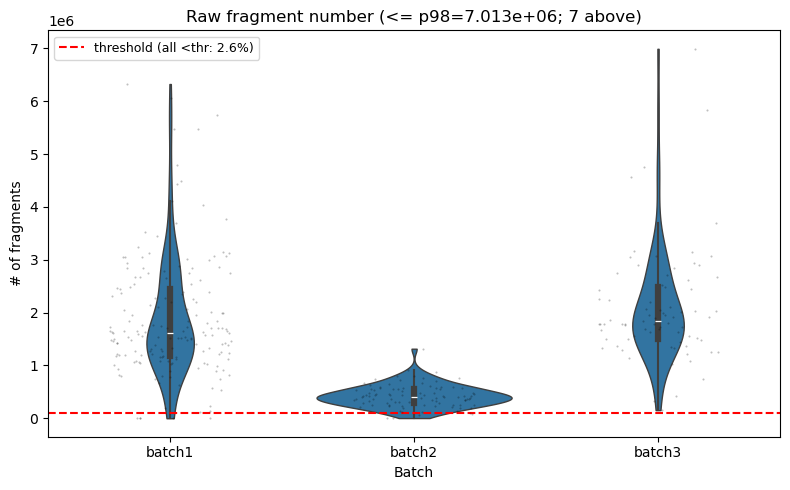

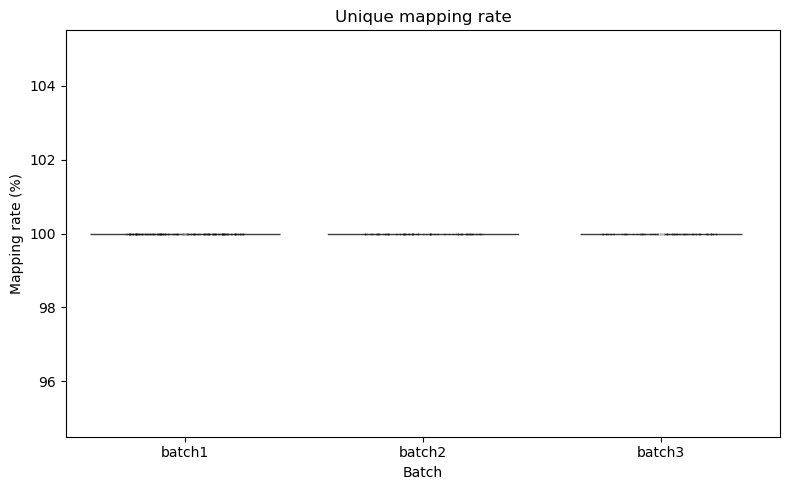

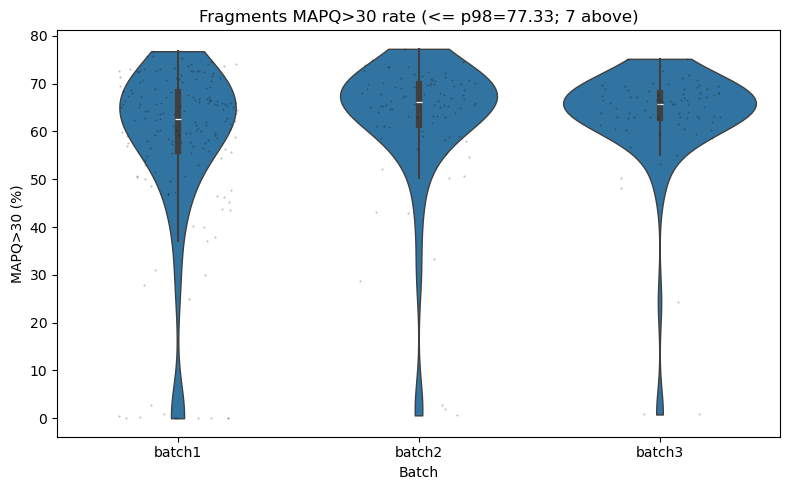

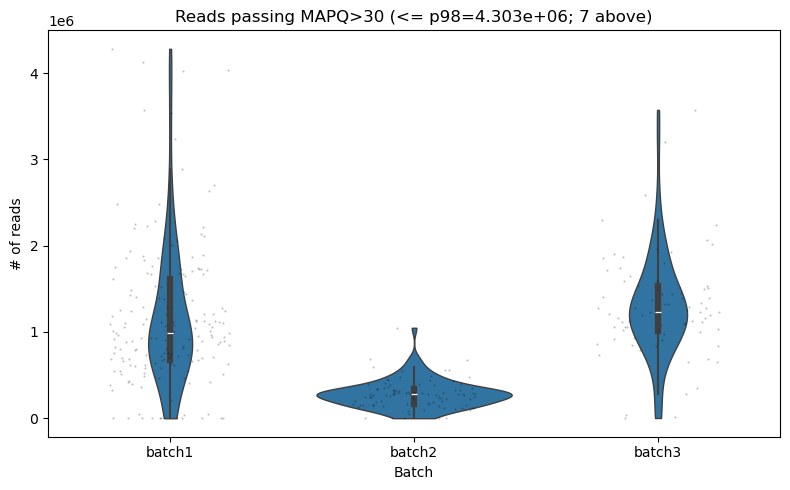

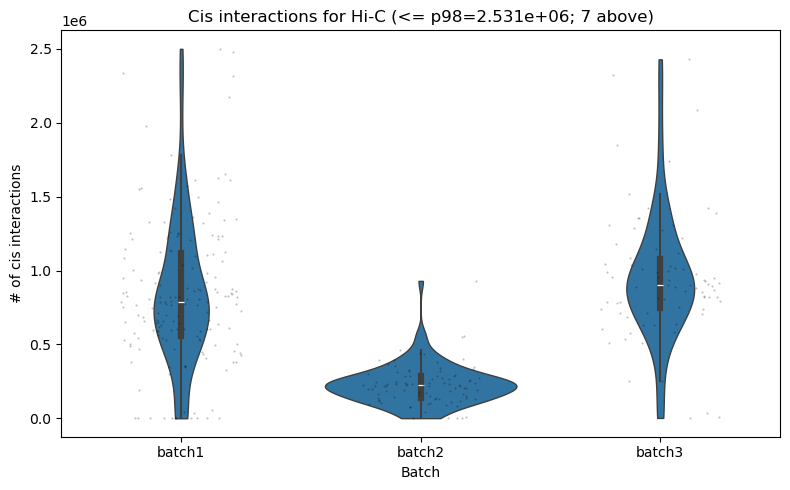

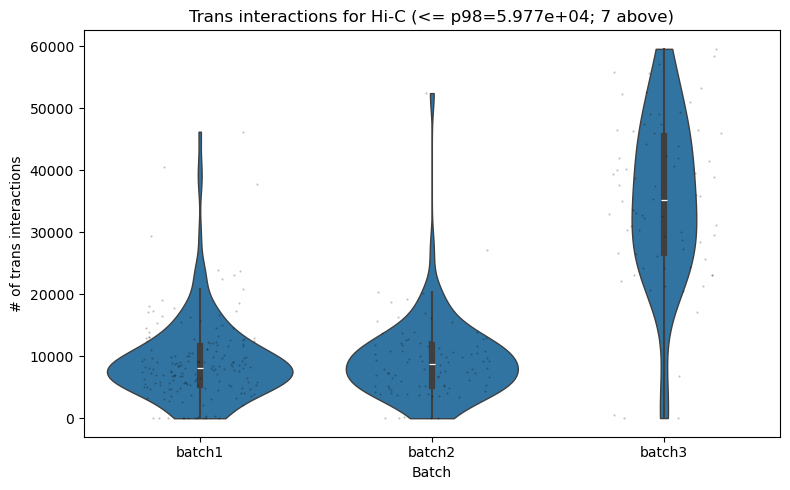

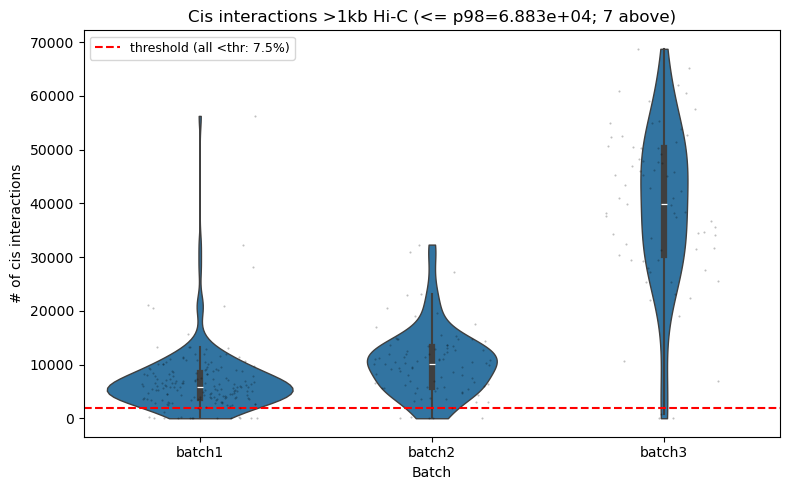

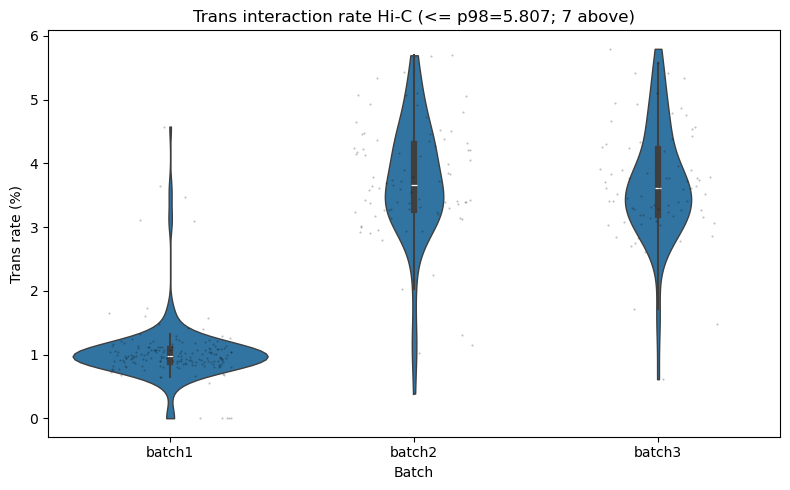

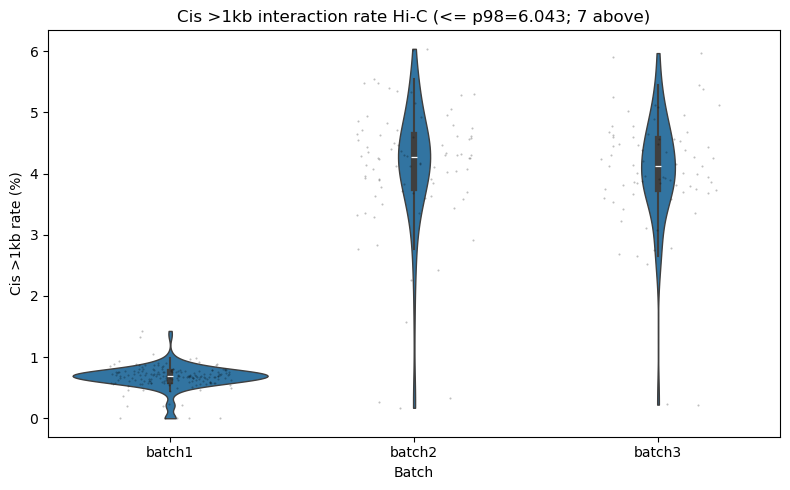

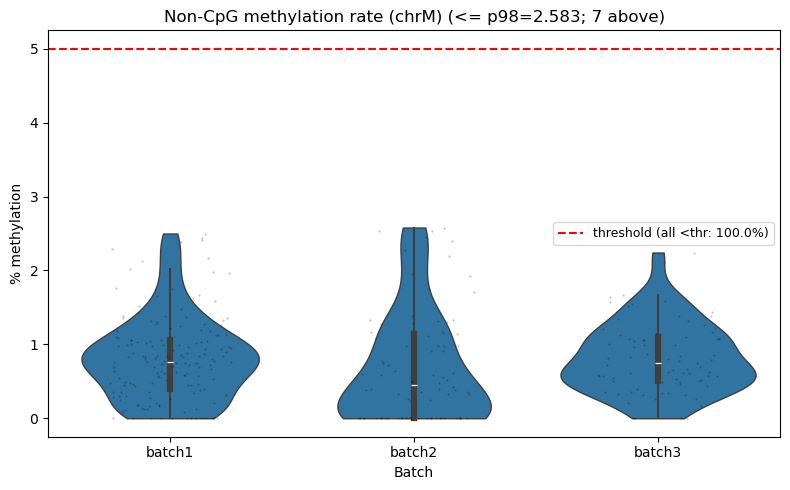

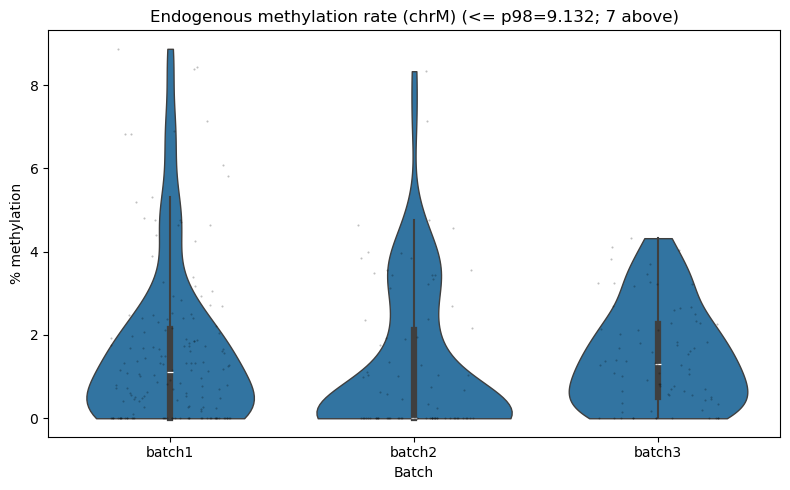

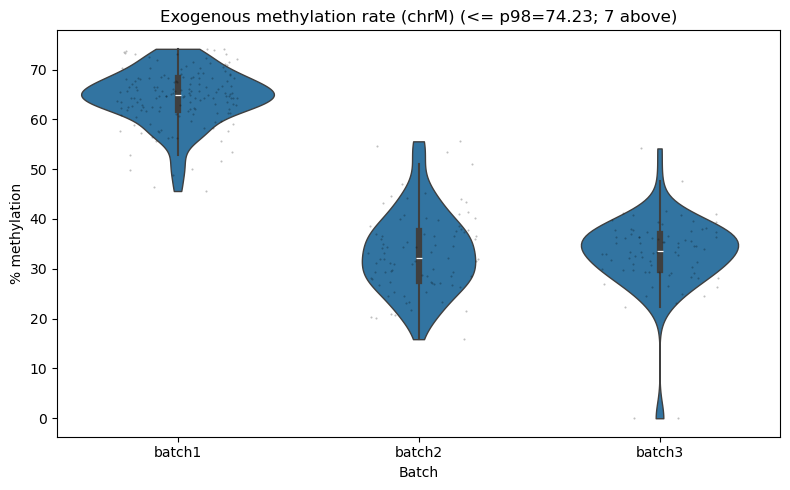

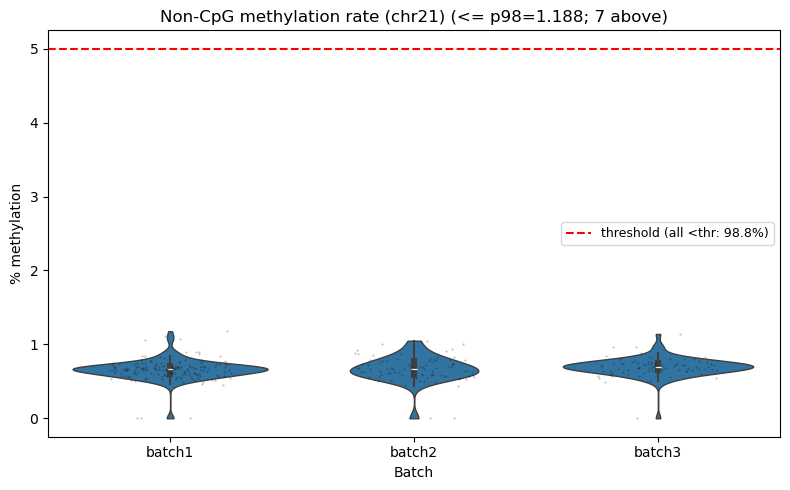

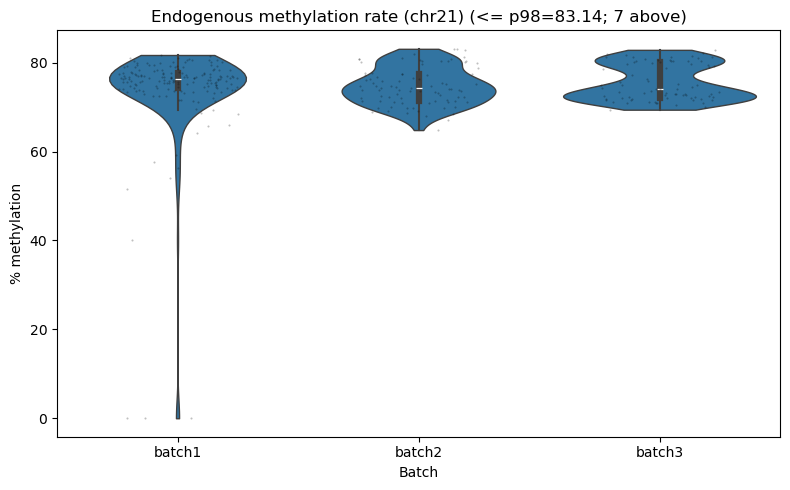

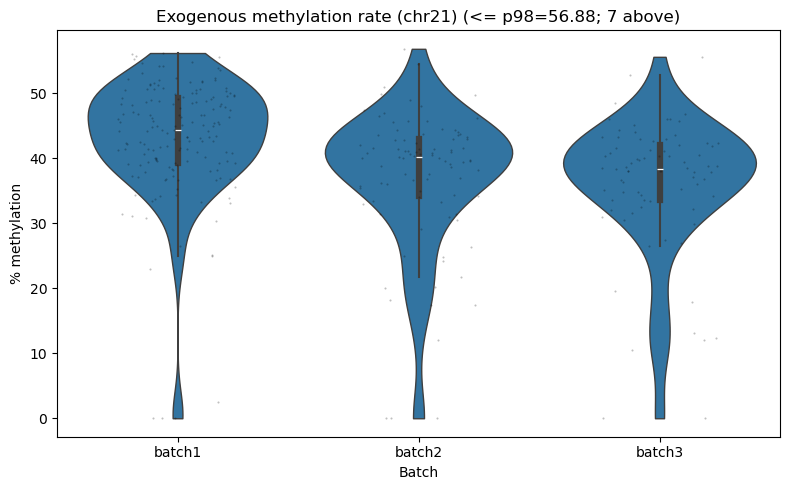

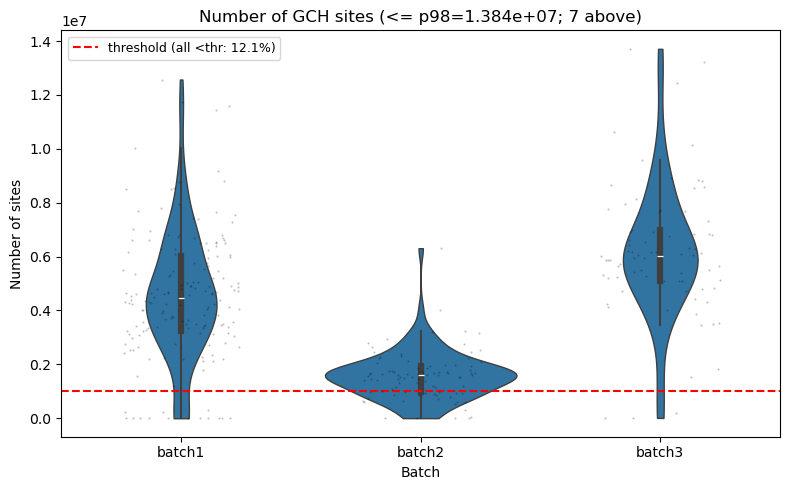

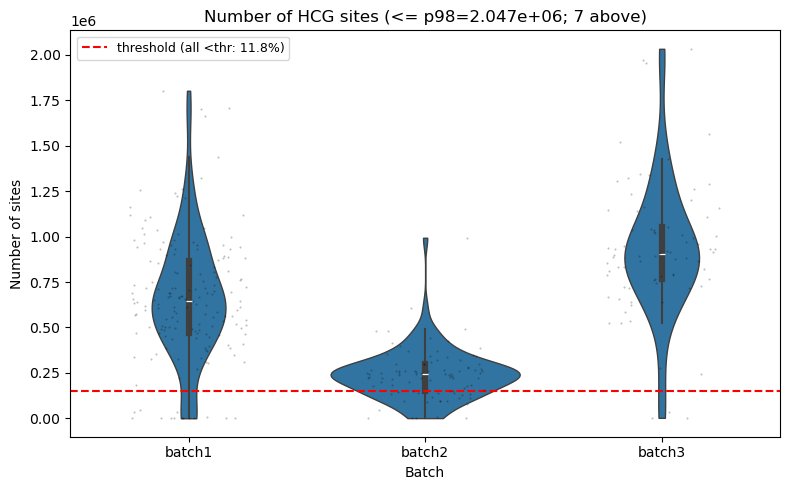

Saved per-batch violin plots: /gpfs/projects/b1198/epifluidlab/yoshii/meningioma_scnomehic/snakemake/figures/meningioma_summary_by_batch_violin_p98_if_outlier.pdf


In [30]:
def plot_violins_per_batch(df, plot_columns, thresholds, batch_order=None,
                           out_pdf=None, show_inline=False,
                           clip_percentile=None, clip_only_if_outlier=False):
    if batch_order is None:
        batch_order = [b for b in BATCH_ORDER if b in set(df['batch'])]
    pdf = PdfPages(out_pdf) if out_pdf else None
    try:
        for col, title, ylabel in plot_columns:
            if col not in df.columns: continue
            plot_df = df[['batch', col]].dropna()
            plot_df = plot_df[plot_df['batch'].isin(batch_order)]
            if plot_df.empty: continue
            thr = thresholds.get(col); title_use = title
            if clip_percentile is not None:
                x_hi = float(np.percentile(plot_df[col], clip_percentile))
                n_above = int((plot_df[col] > x_hi).sum())
                if (n_above > 0) if clip_only_if_outlier else True:
                    plot_df = plot_df[plot_df[col] <= x_hi]
                    title_use = f"{title} (<= p{clip_percentile:.0f}={x_hi:.4g}; {n_above} above)"
            fig, ax = plt.subplots(figsize=(8, 5))
            sns.violinplot(data=plot_df, x='batch', y=col, order=batch_order,
                           inner='box', cut=0, linewidth=1, ax=ax)
            sns.stripplot(data=plot_df, x='batch', y=col, order=batch_order,
                          color='black', size=1.5, alpha=0.25, jitter=0.25, ax=ax)
            if thr is not None:
                av = df[col].dropna()
                ax.axhline(thr, color='red', linestyle='--', linewidth=1.5,
                           label=f'threshold (all <thr: {100.0*(av<thr).sum()/len(av):.1f}%)')
                ax.legend(loc='best', fontsize=9)
            ax.set_title(title_use); ax.set_xlabel('Batch'); ax.set_ylabel(ylabel)
            fig.tight_layout()
            if pdf is not None: pdf.savefig(fig, bbox_inches='tight')
            if show_inline: plt.show()
            plt.close(fig)
    finally:
        if pdf is not None: pdf.close()
    if out_pdf is not None:
        print(f'Saved per-batch violin plots: {out_pdf}')


plot_violins_per_batch(
    df_all, PLOT_COLUMNS, METRIC_THRESHOLDS, batch_order=BATCH_ORDER,
    out_pdf=OUT_FIG / 'meningioma_summary_by_batch_violin_p98_if_outlier.pdf',
    clip_percentile=98, clip_only_if_outlier=True, show_inline=True,
)


## Doublet inspection — UNCLIPPED full-range histograms

Doublets / over-amplified cells appear as an abnormally high tail in the
cis-contact depth metrics (`cisnum` is the cleanest signal). The summary
histograms above clip the top at p98/p99, which hides exactly that tail — so
these are **full-range, NOT clipped**, with a **log-y** twin so the sparse
high tail is visible. A rank plot + a top-cells table give the actual values.

Use these to choose **`cisnum_max_threshold`** (an UPPER bound — a cell passes
iff `cisnum < threshold`). Then add it to `config.yaml` and re-run the
"Alignment summaries … write meningioma_passed.txt" cell to re-filter, then the
HiC usability cell. Until set, no doublet filter is applied (`cisnum_max_threshold`
defaults to +inf).

> Note: a high `cisnum` can also just mean a deeply-sequenced *single* cell
> (e.g. the very deepest cell here is a real singlet), so eyeball the gap
> between the main population and the outliers rather than cutting the top blindly.

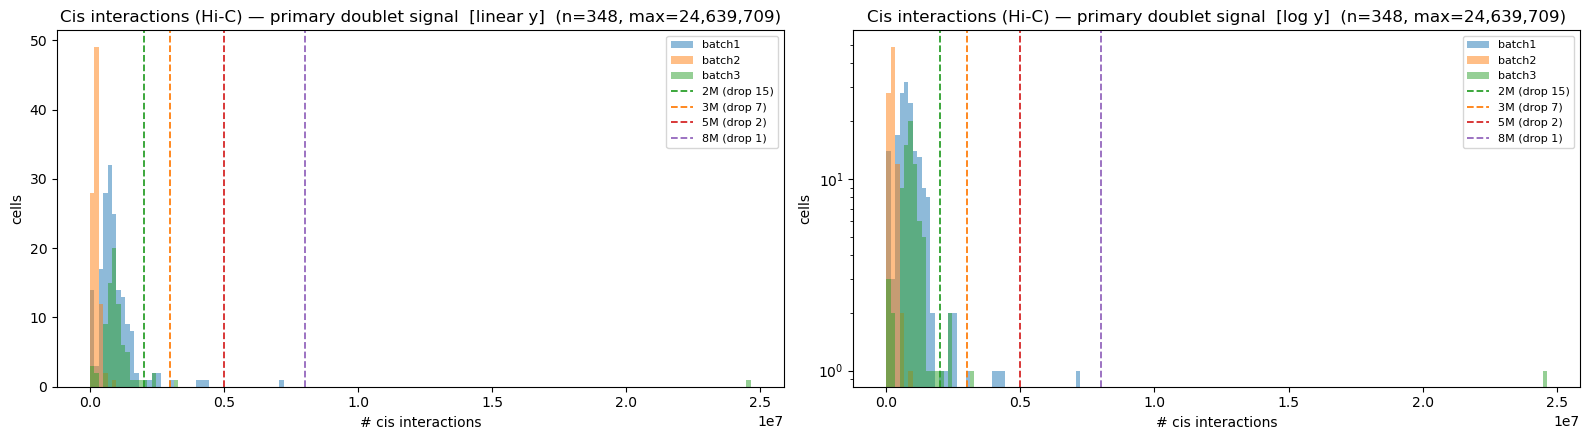

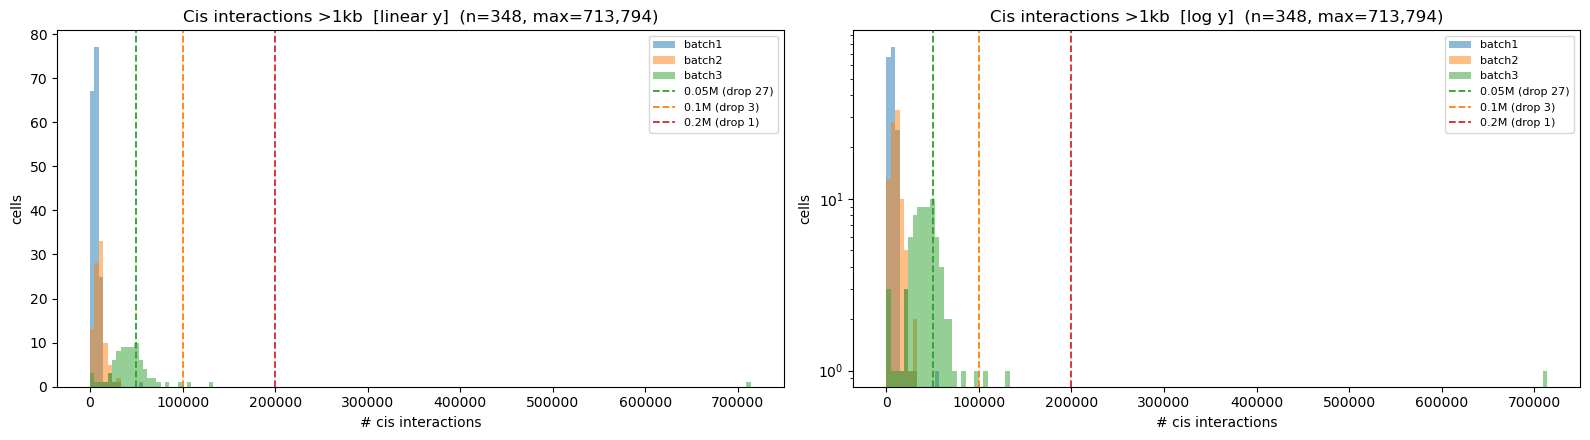

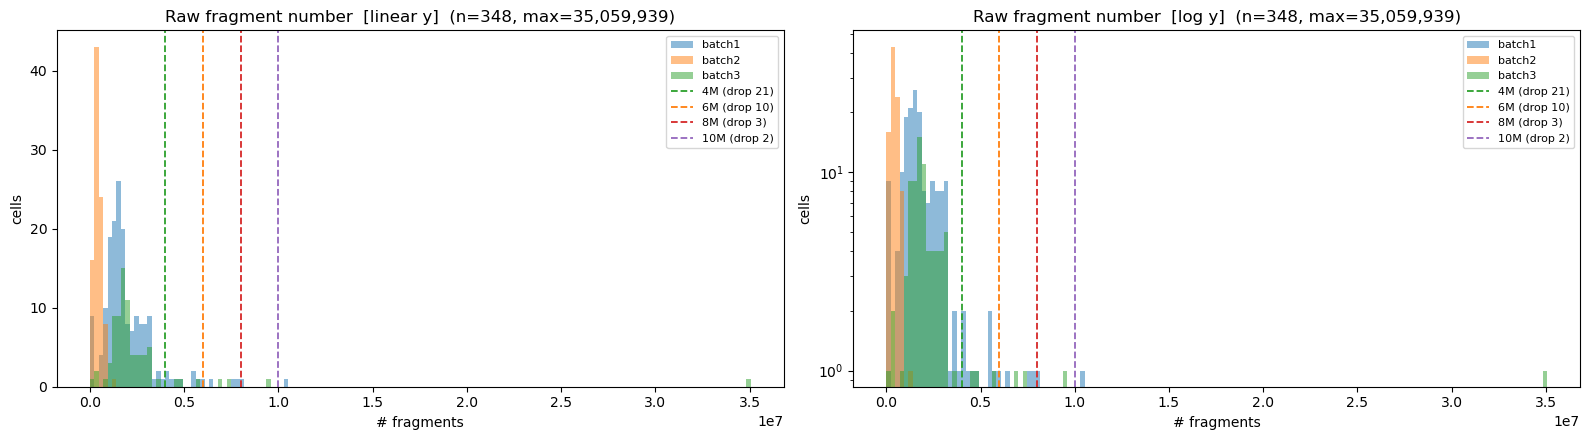

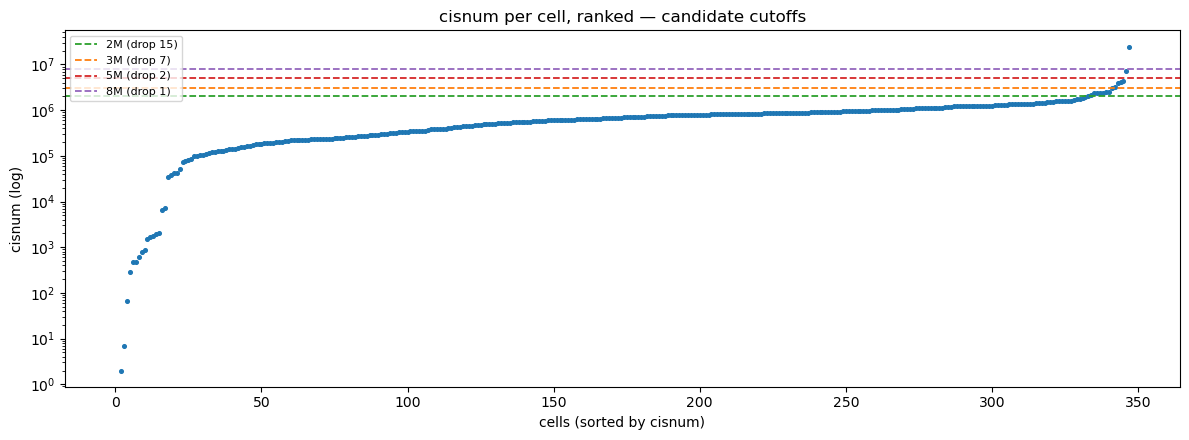

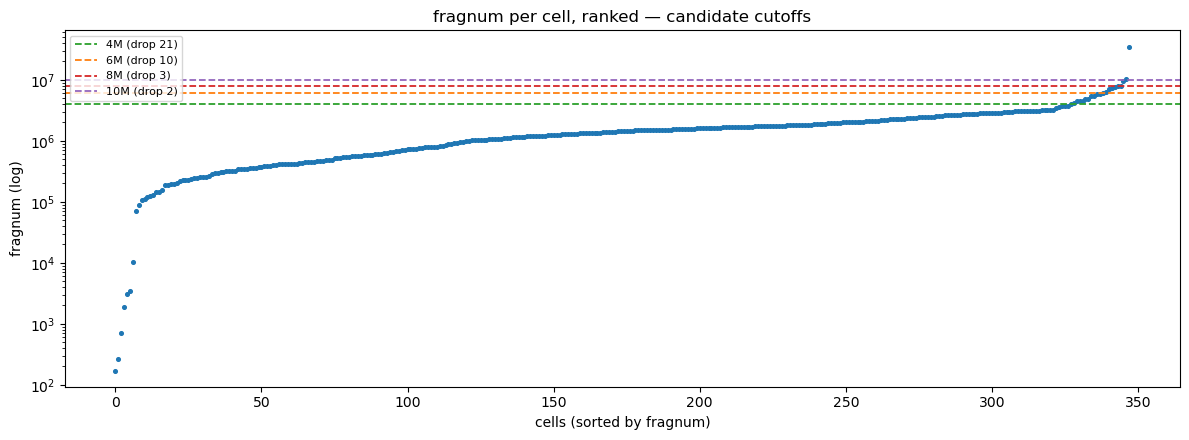

Top 20 cells by cisnum (candidate doublets / deep singlets):
                                   prefix  batch   cisnum  cis1kbnum  fragnum
NU04113_scNOMe_HiC_p2_01_250409_S1.ATCACG batch3 24639709     713794 35059939
                        MY_24_S206.TGACCA batch1  7109879      56289 10473240
                        MY_14_S197.ATCACG batch1  4283378      28084  6324407
                         MY_2_S185.ATCACG batch1  4146188      20927  5473379
                        MY_39_S220.ACTTGA batch1  3971143      32222  7669935
NU04113_scNOMe_HiC_p2_06_250409_S6.GCCAAT batch3  3210894     131644  9420211
                        MY_46_S225.ACTTGA batch1  3000841      21173  5464558
                        MY_10_S193.ATCACG batch1  2500967      13022  7953474
                        MY_10_S193.TGACCA batch1  2481754      13181  6063240
NU04113_scNOMe_HiC_p2_06_250409_S6.TGACCA batch3  2429669      97259  7372307
                        MY_44_S223.TAGCTT batch1  2334331      15683  4800198
NU0

In [31]:
# Full-range (UNCLIPPED) histograms for doublet-threshold picking.
DOUBLET_METRICS = [
    ('cisnum',    'Cis interactions (Hi-C) — primary doublet signal', '# cis interactions'),
    ('cis1kbnum', 'Cis interactions >1kb',                            '# cis interactions'),
    ('fragnum',   'Raw fragment number',                              '# fragments'),
]
DOUBLET_NBINS = 150
# Candidate upper-bound cutoffs drawn as labeled vertical lines (with how many
# cells each would drop) so you can pick a threshold visually. Edit freely.
CANDIDATE_CUTS = {
    'cisnum':    [2_000_000, 3_000_000, 5_000_000, 8_000_000],
    'cis1kbnum': [50_000, 100_000, 200_000],
    'fragnum':   [4_000_000, 6_000_000, 8_000_000, 10_000_000],
}
_CUT_COLORS = ['tab:green', 'tab:orange', 'tab:red', 'tab:purple', 'tab:brown']

for col, title, xlabel in DOUBLET_METRICS:
    vals = df_all[col].dropna()
    if vals.empty:
        continue
    bins = np.linspace(float(vals.min()), float(vals.max()), DOUBLET_NBINS + 1)
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
    for ax, yscale in zip(axes, ('linear', 'log')):
        for b in BATCH_ORDER:
            bv = df_all.loc[df_all['batch'] == b, col].dropna()
            if not bv.empty:
                ax.hist(bv, bins=bins, alpha=0.5, label=b)
        for t, c in zip(CANDIDATE_CUTS.get(col, []), _CUT_COLORS):
            n = int((vals >= t).sum())
            ax.axvline(t, color=c, ls='--', lw=1.3,
                       label=f'{t/1e6:g}M (drop {n})')
        ax.set_yscale(yscale)
        ax.set_title(f'{title}  [{yscale} y]  (n={len(vals)}, max={vals.max():,.0f})')
        ax.set_xlabel(xlabel); ax.set_ylabel('cells')
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT_FIG / f'doublet_{col}_unclipped.pdf', bbox_inches='tight')
    plt.show(); plt.close(fig)

# Ranked plots (log y) with the same candidate cutoffs as horizontal lines —
# outliers sit at the far-right top; pick where the tail separates.
for col in ['cisnum', 'fragnum']:
    s = df_all[[col]].dropna().sort_values(col).reset_index(drop=True)
    vals = df_all[col].dropna()
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.scatter(range(len(s)), s[col], s=7)
    for t, c in zip(CANDIDATE_CUTS.get(col, []), _CUT_COLORS):
        n = int((vals >= t).sum())
        ax.axhline(t, color=c, ls='--', lw=1.3, label=f'{t/1e6:g}M (drop {n})')
    ax.set_yscale('log'); ax.set_xlabel(f'cells (sorted by {col})'); ax.set_ylabel(f'{col} (log)')
    ax.set_title(f'{col} per cell, ranked — candidate cutoffs')
    ax.legend(fontsize=8, loc='upper left')
    fig.tight_layout(); fig.savefig(OUT_FIG / f'doublet_{col}_ranked.pdf', bbox_inches='tight')
    plt.show(); plt.close(fig)

# Actual high-end values so you can read off a threshold.
print('Top 20 cells by cisnum (candidate doublets / deep singlets):')
print(df_all.nlargest(20, 'cisnum')[['prefix', 'batch', 'cisnum', 'cis1kbnum', 'fragnum']].to_string(index=False))
print('\ncisnum distribution percentiles:')
print(df_all['cisnum'].describe(percentiles=[.5, .9, .95, .99]).to_string())


## Cell x bin methylation matrices

Dense `cells x bins` matrices from `08.methylation_snakemake/*.{GCH,HCG}.<label>_methylation.txt.gz`.
Bin labels come from `config.yaml` (`methylation_bin_sizes` + `methylation_region_beds` keys:
`gene_tss`, `gene_body`, `gene`). Incremental: skips matrices already newer than their inputs.
Set `USE_QC_PASSED_ONLY = True` to restrict to `meningioma_passed.txt`.

In [ ]:
OUT_MATRIX = OUT_QC / 'methylation_matrices'
OUT_MATRIX.mkdir(exist_ok=True)
METH_BIN_DIR = WORKDIR / '08.methylation_snakemake'

USE_QC_PASSED_ONLY = False
FORCE_REBUILD      = False


def _bin_size_to_label(n):
    n = int(n)
    if n >= 1_000_000 and n % 1_000_000 == 0: return f'{n // 1_000_000}Mb'
    if n >= 1000 and n % 1000 == 0:           return f'{n // 1000}kb'
    return f'{n}bp'

SIZE_LABELS   = [_bin_size_to_label(n) for n in CFG.get('methylation_bin_sizes', [])]
REGION_LABELS = list((CFG.get('methylation_region_beds') or {}).keys())
ALL_LABELS    = SIZE_LABELS + REGION_LABELS
CONTEXTS      = ['GCH', 'HCG']
print('fixed bins:', SIZE_LABELS, '| regions:', REGION_LABELS)


def _cell_from_path(path, context, bin_label):
    suffix = f'.{context}.{bin_label}_methylation.txt.gz'
    return Path(path).name[:-len(suffix)]


def build_methylation_matrix(context, bin_label, cells=None):
    files = sorted(METH_BIN_DIR.glob(f'*.{context}.{bin_label}_methylation.txt.gz'))
    if not files:
        raise FileNotFoundError(f'no files for {context}/{bin_label}')
    if cells is not None:
        cells = set(cells)
        files = [f for f in files if _cell_from_path(f, context, bin_label) in cells]
    rows = []
    for path in tqdm(files, desc=f'{context} {bin_label}'):
        cell = _cell_from_path(path, context, bin_label)
        d = pd.read_csv(path, sep='\t', usecols=['bin_id', 'methylation_level'])
        rows.append(d.set_index('bin_id')['methylation_level'].rename(cell))
    mat = pd.concat(rows, axis=1).T
    mat.index.name = 'cell'
    return mat


def save_bin_coords(bin_label, out_path):
    ref = next(METH_BIN_DIR.glob(f'*.GCH.{bin_label}_methylation.txt.gz'))
    pd.read_csv(ref, sep='\t', usecols=['bin_id', 'chr', 'start', 'end']).to_csv(out_path, sep='\t', index=False)


def newest_input_mtime(context, bin_label):
    files = sorted(METH_BIN_DIR.glob(f'*.{context}.{bin_label}_methylation.txt.gz'))
    return max((f.stat().st_mtime for f in files), default=-1)


cells_filter = None
if USE_QC_PASSED_ONLY:
    pp = OUT_QC / 'meningioma_passed.txt'
    if pp.exists():
        cells_filter = pd.read_csv(pp, header=None)[0].tolist()
        print(f'Filtering to {len(cells_filter)} QC-passed cells')

for label in ALL_LABELS:
    coords = OUT_MATRIX / f'bins_{label}.tsv'
    if FORCE_REBUILD or not coords.exists():
        try:
            save_bin_coords(label, coords)
        except StopIteration:
            print(f'no per-cell files for label={label}; skipping'); continue
    for context in CONTEXTS:
        out_file = OUT_MATRIX / f'methylation_matrix_{context}_{label}.tsv.gz'
        in_mtime = newest_input_mtime(context, label)
        if in_mtime < 0:
            print(f'no files for {context}/{label}; skipping'); continue
        if (not FORCE_REBUILD) and out_file.exists() and out_file.stat().st_mtime > in_mtime:
            print(f'up-to-date: {context} {label}'); continue
        mat = build_methylation_matrix(context, label, cells=cells_filter)
        mat.to_csv(out_file, sep='\t', compression='gzip')
        print(f'{context} {label}: {mat.shape[0]} cells x {mat.shape[1]} bins -> {out_file.name}')


## Hi-C usability check (run after per-cell HiC matrices exist)

Drops methylation-QC-passed cells whose Hi-C input would make `hicluster` crash.
`generatematrix-cell` writes a per-chromosome matrix only if that chromosome has
**>=1 cis contact** with **distance > 2.5 kb** AND **both ends in different
res-sized (250 kb) bins**. If any autosome lacks such a contact, `imputecell`
later dies with `OSError: ... _chr{N}.txt not found`. This cell implements that
**exact** condition (gated on the largest configured resolution).

**Prerequisite:** the per-cell `06.hiccluster_snakemake/{cell}.hic_matrix.txt.gz`
must already exist — i.e. run `code/hic1_matrices.sh` (scbam2hic + hicprocess on
the methylation-passed cells) **before** running this cell.

**Outputs:**
- `QC/meningioma_passed_hicusable.txt` — HiC-usable cells, all three batches (-> `config_hic_all3.yaml`)
- `QC/meningioma_passed_hicusable_batch23.txt` — HiC-usable batch2+3 subset (-> `config_hic_batch23.yaml`)

In [ ]:
import gzip
import re
import multiprocessing as mp

HIC_DIR              = WORKDIR / '06.hiccluster_snakemake'
MIN_HIC_MATRIX_BYTES = 200      # gzip-empty is ~20 bytes
MIN_CIS_DIST_BP      = 2500     # generatematrix's hard minimum cis distance
MIN_PER_CHR          = 1        # need >=1 surviving contact per autosome
MAX_RES              = max(CFG.get('hicluster_resolutions') or [250000])  # 250 kb


def _autosomes():
    sizes = Path(str(CFG['reference']) + '.chrom.sizes')
    if sizes.exists():
        out = {m.group(1) for ln in open(sizes)
               for m in [re.match(r'^(chr[0-9]+)\b', ln)] if m}
        if out:
            return out
    return {f'chr{i}' for i in range(1, 23)}
AUTOSOMES = _autosomes()


def _hic_usable(prefix):
    """Exact generatematrix gate: each autosome needs >=1 cis contact with
    dist > MIN_CIS_DIST_BP AND ends in different MAX_RES bins."""
    p = HIC_DIR / f'{prefix}.hic_matrix.txt.gz'
    if not p.exists() or p.stat().st_size < MIN_HIC_MATRIX_BYTES:
        return prefix, False, {}
    counts = {c: 0 for c in AUTOSOMES}
    try:
        with gzip.open(p, 'rt') as f:
            for ln in f:
                a = ln.split('\t')
                if len(a) < 7:
                    continue
                c1, p1, c2, p2 = a[1], a[2], a[5], a[6]
                if c1 != c2 or c1 not in AUTOSOMES:
                    continue
                p1 = int(p1); p2 = int(p2)
                if abs(p1 - p2) > MIN_CIS_DIST_BP and (p1 // MAX_RES) != (p2 // MAX_RES):
                    counts[c1] += 1
    except Exception:
        return prefix, False, counts
    ok = all(counts[c] >= MIN_PER_CHR for c in AUTOSOMES)
    return prefix, ok, counts


candidates = pd.read_csv(OUT_QC / 'meningioma_passed.txt', header=None)[0].tolist()
n_have_matrix = sum((HIC_DIR / f'{p}.hic_matrix.txt.gz').exists() for p in candidates)
print(f'methylation-passed cells: {len(candidates)} | with hic_matrix on disk: {n_have_matrix}')
if n_have_matrix < len(candidates):
    print('WARNING: some hic_matrix files missing -> run code/hic1_matrices.sh first '
          '(cells without a matrix will be dropped as non-usable).')
print(f'Exact gate: >=1 cis contact [dist > {MIN_CIS_DIST_BP} bp AND different '
      f'{MAX_RES//1000} kb bins] per autosome ({len(AUTOSOMES)} autosomes)')

with mp.Pool(min(16, mp.cpu_count())) as pool:
    results = list(tqdm(pool.imap_unordered(_hic_usable, candidates, chunksize=8),
                        total=len(candidates), desc='hic_matrix scan'))

usable  = sorted(p for p, ok, _ in results if ok)
dropped = [(p, c) for p, ok, c in results if not ok]
print(f'\nHiC-usable: {len(usable)}/{len(candidates)}  (dropped {len(dropped)})')
for p, counts in dropped[:25]:
    if not counts:
        print(f'    drop {p}  (no/empty hic_matrix)')
    else:
        bad = [c for c in sorted(AUTOSOMES, key=lambda x: int(x[3:]))
               if counts.get(c, 0) < MIN_PER_CHR]
        print(f'    drop {p}  (failing chrs: {bad[:6]}{"..." if len(bad) > 6 else ""})')
if len(dropped) > 25:
    print(f'    ... and {len(dropped) - 25} more')

# Two whitelists for the two hicluster runs.
pd.Series(usable).to_csv(OUT_QC / 'meningioma_passed_hicusable.txt', index=False, header=False)
b23 = [p for p in usable if assign_batch(p) in ('sample2_plate1', 'sample2_plate2')]
pd.Series(b23).to_csv(OUT_QC / 'meningioma_passed_hicusable_batch23.txt', index=False, header=False)
from collections import Counter
print('\nHiC-usable by batch:', dict(Counter(assign_batch(p) for p in usable)))
print(f'wrote QC/meningioma_passed_hicusable.txt          ({len(usable)} cells, all 3 batches)')
print(f'wrote QC/meningioma_passed_hicusable_batch23.txt  ({len(b23)} cells, batch2+3)')
